# **DATA SCIENCE**


**OUTLIERS**


In [92]:
import numpy as np
arr = np.array([2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,23,25,37,201])

In [93]:
q1 = np.percentile(arr,25)
q2 = np.percentile(arr,50)
q3 = np.percentile(arr,75)

IQR = q3-q1
UF = q3 + 1.5*(IQR)
LF = q1 - 1.5*(IQR)

In [94]:

l=[]
for i in arr:
    if i<= UF and i>=LF:
        l.append(i)
arr2 = np.array(l)

<Axes: >

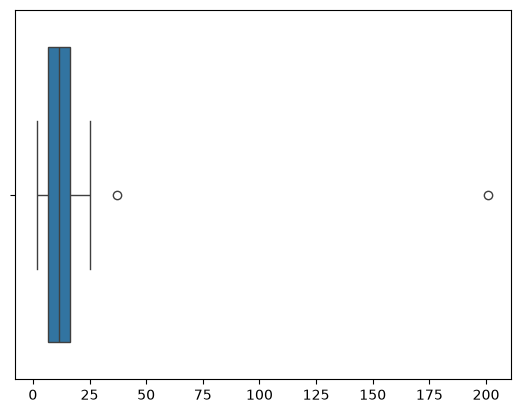

In [95]:
import seaborn as sns
sns.boxplot(x=arr)

<Axes: >

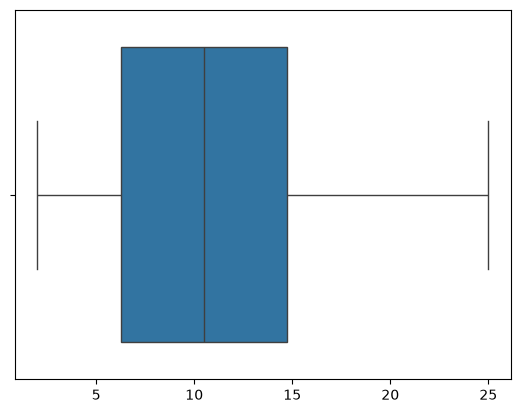

In [96]:
sns.boxplot(x=arr2)

**Z TEST**


In [97]:
import numpy as np
from scipy.stats import norm

In [98]:
sample = [172, 174, 168,169 , 171, 173, 
          175, 170, 169,162, 146,199,145
          , 172, 150,130,142,145,163,163,
          163, 145, 145, 134, 163, 145, 146,
          165, 146, 175, 140]
population_mean = 170
population_std=3
samp_mean = np.mean(sample)
n = len(sample)

In [99]:
z_score = (samp_mean - population_mean) / (population_std/np.sqrt(n))

In [100]:
z_score

-20.654609733079106

In [101]:
p_value = 2 * (1 - norm.cdf(z_score))
alpha = 0.05

if p_value < alpha:
    print("I will reject the null hypothesis")
else:
    print("I will accpet the null hypothesis")

I will accpet the null hypothesis


**T-TEST**


In [102]:
import numpy as np
from scipy import stats

In [103]:
sample = [172,174,168,169,171, 173, 175, 170, 169, 172]
sample_mean = np.mean(sample)
sample_std = np.std(sample, ddof=1)
n = len(sample)
mean_population = 170

In [104]:
t_stats = (sample_mean - population_mean) / (sample_std / np.sqrt(n))
t_stats

1.7782469350914734

In [105]:
p_value = 2 * (1 - stats.t.cdf(abs(t_stats),df = n-1))
alpha = 0.05

In [106]:
if p_value < alpha:
    print("Reject the null hypothesis")
else:
    print("Accept the null hypothesis")

Accept the null hypothesis


**TWO SAMPLE TEST**


In [107]:
import numpy as np
from scipy import stats

In [108]:
group_A = [85, 88, 90, 92, 87, 85, 89, 91, 86, 88]
group_B = [82, 84, 80, 83, 81, 79, 78, 85, 84, 83]

In [109]:
t_stats , p_value = stats.ttest_ind(group_A,group_B, equal_var=False)

In [110]:
alpha = 0.05

In [111]:
if p_value < alpha:
    print("Reject the null hypothesis")
else:
    print("Accept the null hypothesis")

Reject the null hypothesis


**CHI SQAURE TEST**


In [112]:
import numpy as np
import seaborn as sns
from scipy.stats import chi2_contingency
import pandas as pd

In [113]:
df = sns.load_dataset('titanic')

In [114]:
df

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
886,0,2,male,27.0,0,0,13.0000,S,Second,man,True,NaN,Southampton,no,True
887,1,1,female,19.0,0,0,30.0000,S,First,woman,False,B,Southampton,yes,True
888,0,3,female,NaN,1,2,23.4500,S,Third,woman,False,NaN,Southampton,no,False
889,1,1,male,26.0,0,0,30.0000,C,First,man,True,C,Cherbourg,yes,True


In [115]:
contingency_table = pd.crosstab(df['sex'],df['survived'])

In [116]:
contingency_table

survived,0,1
sex,,
female,81,233
male,468,109


In [117]:
chi2, p_value, dof , expected = chi2_contingency(contingency_table)

In [118]:
expected

array([[193.47474747, 120.52525253],
       [355.52525253, 221.47474747]])

In [119]:
dof

1

In [120]:
p_value

1.1973570627755645e-58

In [121]:
chi2

260.71702016732104

In [122]:
alpha = 0.05

In [123]:
if p_value < alpha:
    print("REJECT NULL HYPOTHESIS AS THEIR IS A SIGNIFICANT RELATIONSHIP BETWEEN GENDER AND SURVIVAL")
else:
    print("ACCEPT NULL HYPOTHESIS AS THEIR IS NO SIGNIFICANT RELATIONSHIP BETWEEN GENDER AND SURVIVAL")

REJECT NULL HYPOTHESIS AS THEIR IS A SIGNIFICANT RELATIONSHIP BETWEEN GENDER AND SURVIVAL


**ANOVE TEST**


In [124]:
import seaborn as sns
import pandas as pd
from scipy.stats import f_oneway

In [125]:
df

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
886,0,2,male,27.0,0,0,13.0000,S,Second,man,True,NaN,Southampton,no,True
887,1,1,female,19.0,0,0,30.0000,S,First,woman,False,B,Southampton,yes,True
888,0,3,female,NaN,1,2,23.4500,S,Third,woman,False,NaN,Southampton,no,False
889,1,1,male,26.0,0,0,30.0000,C,First,man,True,C,Cherbourg,yes,True


In [126]:
df['pclass'].unique()

array([3, 1, 2], dtype=int64)

In [138]:
df = df[['age','pclass']].dropna()
df[['age','pclass']]

,age,pclass
0,22.0,3
1,38.0,1
2,26.0,3
3,35.0,1
4,35.0,3
...,...,...
885,39.0,3
886,27.0,2
887,19.0,1
889,26.0,1


In [134]:
class_1 = df[df['pclass'] == 1]['age']
class_2 = df[df['pclass'] == 2]['age']
class_3 = df[df['pclass'] == 3]['age']
class_1

1      38.0
3      35.0
6      54.0
11     58.0
23     28.0
       ... 
871    47.0
872    33.0
879    56.0
887    19.0
889    26.0
Name: age, Length: 186, dtype: float64

In [135]:
f_stats , p_value = f_oneway(class_1, class_2,class_3)

In [136]:
f_stats

57.44348434067624

In [137]:
p_value

7.487984171957403e-24

In [ ]:
if p_value < alpha:
    print("reject the null hypothesis as their is a significant difference in atleast one passenger class")
else:
    print("accept the null hypothesis as their is ")